# 04 Tehnologije i plata

Ulaz: `data/interim/dataset_kanonizovan.parquet` i `data/interim/graf_meta.json`,
koje proizvodi `02_analiza.ipynb`.

Pitanje: koliko se plate uopšte može objasniti onim što piše u oglasu, i koje
tehnologije nose veću platu.

Redosled:

1. koji oglasi ulaze u analizu i po čemu se razlikuju od ostalih
2. koliko se plate može objasniti, poređenje modela i kriva učenja
3. koje grupe tehnologija iz `02_analiza` najviše utiču
4. premija po pojedinačnoj tehnologiji

## 1. Podešavanje i podaci

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

INTERIM = Path("data/interim")
RAW = Path("data/raw")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 220)

SEED = 42
N_JOBS = 2   # dugi nizovi modela na punom opterećenju gase laptop
SEEDOVI = (1, 7, 42, 123, 2026, 5, 11, 77, 2024, 314)   # deset podela

# Rezultat svakog modela na svakoj podeli upisuje se na disk čim se izračuna.
# Prekid (npr. pad računara) ne gubi urađeno; sledeće pokretanje nastavlja.
# Brisanjem foldera se sve računa iznova, na primer posle izmene modela.
KES = INTERIM / "kes_plate"
KES.mkdir(exist_ok=True)


def kesiraj(naziv: str, izracunaj):
    """Vrati sačuvan rezultat ako postoji; inače izračunaj i odmah upiši."""
    putanja = KES / (re.sub(r"[^\w]+", "_", naziv) + ".json")
    if putanja.exists():
        return json.loads(putanja.read_text(encoding="utf-8"))
    rezultat = izracunaj()
    putanja.write_text(json.dumps(rezultat, ensure_ascii=False), encoding="utf-8")
    return rezultat

dataset = pd.read_parquet(INTERIM / "dataset_kanonizovan.parquet")

# Veličina firme nije u dataset.parquet; dolazi preko company_id iz sirovih fajlova.
veza = pd.read_csv(RAW / "postings.csv", usecols=["job_id", "company_id"])
firme = pd.read_csv(RAW / "companies.csv", usecols=["company_id", "company_size"])
dataset = dataset.merge(veza, on="job_id", how="left").merge(firme, on="company_id", how="left")

it = dataset[dataset["is_it_role"]].copy()
print(f"IT oglasa: {len(it):,}")

IT oglasa: 11,713


### Koji oglasi ulaze u analizu

Plata je navedena u manjem delu oglasa. Iznosi po satu, nedelji i mesecu svedeni
su na godišnji nivo još u `01_ekstrakcija`.

Odbacuju se vrednosti ispod 20.000 i iznad 500.000 dolara godišnje. Ispod donje
granice su skraćeni ugovori i honorari upisani kao godišnja plata, iznad gornje
su retki rukovodeći oglasi i očigledne greške u unosu. U oba slučaja bi nekoliko
takvih redova pomerilo procene.

Zavisna promenljiva je logaritam godišnje plate, iz dva razloga:

- raspodela plata je nagnuta udesno, pa logaritam približava raspodelu normalnoj
- razlike postaju procentualne, a ne dolarske. Koeficijent od 0,12 znači oko 12 %
  više, što je uporedivo između mladog i iskusnog kandidata. U dolarima ista
  tehnologija kod seniora vredi više nego kod juniora, pa koeficijent ne bi
  značio jedno.

In [2]:
MIN_PLATA, MAX_PLATA = 20_000, 500_000

it["ima_platu"] = it["godisnja_plata"].between(MIN_PLATA, MAX_PLATA)
plate = it[it["ima_platu"]].copy().reset_index(drop=True)
plate["log_plata"] = np.log(plate["godisnja_plata"])

# obeležja posla koja ulaze u model
plate["drzava"] = plate["location"].astype(str).str.extract(r",\s*([A-Z]{2})\b")[0].fillna("XX")
plate["nivo"] = plate["formatted_experience_level"].fillna("nepoznato")
plate["tip"] = plate["formatted_work_type"].fillna("nepoznato")
plate["velicina_firme"] = plate["company_size"].fillna(-1)
plate["firma"] = plate["company_name"].fillna("__bez_firme_" + plate["job_id"].astype(str))

odbaceno = int(it["godisnja_plata"].notna().sum() - it["ima_platu"].sum())
print(f"IT oglasa sa platom u opsegu : {len(plate):,}  ({len(plate)/len(it)*100:.1f} % svih IT oglasa)")
print(f"odbačeno van opsega          : {odbaceno:,}")
print(f"različitih firmi             : {plate['firma'].nunique():,}")
print(f"\nplata: medijana {plate['godisnja_plata'].median():,.0f} $ | "
      f"kvartili {plate['godisnja_plata'].quantile(.25):,.0f} - {plate['godisnja_plata'].quantile(.75):,.0f} $")
print(f"tehnologija po oglasu: prosek {plate['tech'].apply(len).mean():.2f}")

IT oglasa sa platom u opsegu : 3,411  (29.1 % svih IT oglasa)
odbačeno van opsega          : 66
različitih firmi             : 1,566

plata: medijana 131,600 $ | kvartili 104,000 - 164,500 $
tehnologija po oglasu: prosek 6.98


## 2. Da li su oglasi sa platom drugačiji

Plata se ne navodi slučajno. Ako je navode firme koje traže drugačije
tehnologije, zaključci bi važili samo za taj podskup, a ne za IT tržište.

Provera je poređenje udela svake tehnologije u dve grupe: oglasi sa navedenom
platom i oglasi bez nje. Uz to se porede i obeležja posla.

In [3]:
from scipy import stats

TEHNOLOGIJE = sorted(json.load(open(INTERIM / "graf_meta.json"))["partition"])


def udeli_tehnologija(df: pd.DataFrame) -> pd.Series:
    """Udeo oglasa koji traže svaku tehnologiju."""
    return pd.Series({t: df["tech"].apply(lambda l: l is not None and t in l).mean() for t in TEHNOLOGIJE})


sa_platom = udeli_tehnologija(it[it["ima_platu"]])
bez_plate = udeli_tehnologija(it[~it["ima_platu"]])

print(f"oglasa: sa platom {it['ima_platu'].sum():,} | bez plate {(~it['ima_platu']).sum():,}")
print(f"udeo tehnologija:  Spearman ρ = {stats.spearmanr(sa_platom, bez_plate).statistic:.3f}"
      f"   Pearson r = {stats.pearsonr(sa_platom, bez_plate).statistic:.3f}")

razlika = ((sa_platom - bez_plate) * 100).sort_values()
print(f"razlika u udelu: najveća {razlika.abs().max():.1f} pp, prosečna apsolutna {razlika.abs().mean():.2f} pp")
print("\nnajveće razlike (procentni poeni, + znači češće u oglasima sa platom):")
print(pd.concat([razlika.head(4), razlika.tail(4)]).round(1).to_string())

oglasa: sa platom 3,411 | bez plate 8,302
udeo tehnologija:  Spearman ρ = 0.925   Pearson r = 0.986
razlika u udelu: najveća 2.7 pp, prosečna apsolutna 0.38 pp

najveće razlike (procentni poeni, + znači češće u oglasima sa platom):
JAVA         -2.5
JAVASCRIPT   -1.4
HTML         -1.4
ANGULAR      -1.2
POWER BI      1.5
SQL           1.9
PYTHON        2.7
C++           2.7


In [4]:
for kolona, naziv in [("role_family", "oblast posla"), ("formatted_work_type", "tip zaposlenja"),
                      ("formatted_experience_level", "nivo iskustva")]:
    a = it.loc[it["ima_platu"], kolona].fillna("nepoznato").value_counts(normalize=True) * 100
    b = it.loc[~it["ima_platu"], kolona].fillna("nepoznato").value_counts(normalize=True) * 100
    t = pd.DataFrame({"sa platom %": a, "bez plate %": b}).fillna(0)
    t["razlika"] = t["sa platom %"] - t["bez plate %"]
    print(f"\n{naziv}:")
    print(t.sort_values("razlika").round(1).to_string())


oblast posla:
                      sa platom %  bez plate %  razlika
role_family                                            
software_engineering         36.9         39.2     -2.4
devops_cloud                 12.3         13.7     -1.4
non_it                        0.7          0.9     -0.2
management                    0.6          0.7     -0.1
qa                            2.0          1.9      0.1
it_support                   11.9         11.1      0.8
data                         25.8         24.3      1.5
security                      9.8          8.2      1.6

tip zaposlenja:
                     sa platom %  bez plate %  razlika
formatted_work_type                                   
Contract                    23.4         31.4     -8.0
Internship                   0.5          1.0     -0.5
Volunteer                    0.0          0.2     -0.2
Part-time                    0.8          0.7      0.1
Other                        0.4          0.1      0.2
Temporary              

## 3. Obeležja i podela po firmi

Obeležja su binarni pokazatelji za 189 tehnologija iz mreže u `02_analiza`, plus
četiri obeležja posla: savezna država, nivo iskustva, tip zaposlenja i veličina
firme.

Ta četiri obeležja ulaze u isti model, ravnopravno sa tehnologijama. Postoji
jedan model i jedan rezultat. Bez njih bi se poredili poslovi koji nisu uporedivi,
senior u Kaliforniji i junior u Ohaju.

Kodne šeme su dve, jer modeli traže različito. Linearni model ne može da radi sa
državom zapisanom kao broj, jer bi pretpostavio da je država 12 veća od države 5,
pa njemu ide po jedna kolona za svaku vrednost. Stablima to ne smeta, pa dobijaju
kompaktniju šemu sa brojčanim oznakama.

Podela na učenje i proveru ide po firmi, kao u `03_preporuka`. Ovde je to važnije
nego tamo: ista firma plaća slične poslove slično, pa bi model koji je video njene
oglase na proveri pogađao njen platni razred umesto vrednosti tehnologija. Koliko
to tačno menja rezultat meri se u sekciji 4.

In [5]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

OBELEZJA_POSLA = ["drzava", "nivo", "tip", "velicina_firme"]


def matrica_tehnologija(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({t: df["tech"].apply(lambda l: int(l is not None and t in l)).to_numpy() for t in TEHNOLOGIJE},
                        index=df.index)


X_tehnologije = matrica_tehnologija(plate)

# za stabla: kategorije kao brojčane oznake
X_stablo_posao = pd.DataFrame({k: plate[k].astype("category").cat.codes for k in OBELEZJA_POSLA[:3]}, index=plate.index)
X_stablo_posao["velicina_firme"] = plate["velicina_firme"].to_numpy()

# za linearni model: po jedna kolona za svaku vrednost
X_lin_posao = pd.get_dummies(plate[OBELEZJA_POSLA[:3]].astype(str), drop_first=True).astype(float)
X_lin_posao["velicina_firme"] = plate["velicina_firme"].to_numpy()

y = plate["log_plata"].to_numpy()
grupe = plate["firma"].to_numpy()


def podeli(seed: int, po_firmi: bool = True):
    """Vraća indekse (učenje, provera).  Po firmi: 25 % firmi ide u proveru."""
    if po_firmi:
        return next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(X_tehnologije, groups=grupe))
    return train_test_split(np.arange(len(plate)), test_size=0.25, random_state=seed)


uc, pr = podeli(SEED)
print(f"tehnologija kao obeležja: {X_tehnologije.shape[1]}")
print(f"obeležja posla, stabla: {X_stablo_posao.shape[1]} kolona | linearni: {X_lin_posao.shape[1]} kolona")
print(f"\nučenje : {len(uc):>5,} oglasa ({plate.loc[uc, 'firma'].nunique():,} firmi)")
print(f"provera: {len(pr):>5,} oglasa ({plate.loc[pr, 'firma'].nunique():,} firmi)")
assert not set(plate.loc[uc, "firma"]) & set(plate.loc[pr, "firma"])

tehnologija kao obeležja: 189
obeležja posla, stabla: 4 kolona | linearni: 60 kolona

učenje : 2,513 oglasa (1,174 firmi)
provera:   898 oglasa (392 firmi)


## 4. Koliko se plate uopšte može objasniti

Pre pitanja koja tehnologija donosi više ide pitanje koliko se od plate uopšte
vidi iz oglasa. Ako je odgovor malo, to je nalaz koji se mora znati pre nego što
se tumači bilo koja premija.

Mere se tri skupa obeležja, da se vidi šta koliko nosi:

- samo obeležja posla: lokacija, nivo, tip, veličina firme
- samo tehnologije: 189 pokazatelja
- sve zajedno

I dva modela:

- linearni, grebena regresija, koja pretpostavlja da se doprinosi sabiraju
- Random Forest, koji može da uhvati nelinearnost i interakcije, na primer da
  Kubernetes vredi drugačije kod seniora nego kod juniora

R² se čita kao udeo objašnjene razlike u logaritmu plate. Nula znači da model
nije bolji od prosečne plate za svakoga.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score

ALFE = np.logspace(-2, 3, 20)


def oceni(skup: str, model: str, seed: int, po_firmi: bool = True) -> dict:
    uc, pr = podeli(seed, po_firmi)
    posao = X_stablo_posao if model == "Random Forest" else X_lin_posao
    delovi = {"samo posao": [posao], "samo tehnologije": [X_tehnologije], "sve": [X_tehnologije, posao]}[skup]
    X = pd.concat(delovi, axis=1)
    m = (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=N_JOBS, random_state=42)
         if model == "Random Forest" else RidgeCV(alphas=ALFE))
    m.fit(X.iloc[uc], y[uc])
    p = m.predict(X.iloc[pr])
    return {"obeležja": skup, "model": model, "seed": seed,
            "R²": r2_score(y[pr], p), "MAE": mean_absolute_error(y[pr], p)}


rezultati = pd.DataFrame([kesiraj(f"oceni|{s}|{m}|{seed}|True", lambda: oceni(s, m, seed))
                          for s in ("samo posao", "samo tehnologije", "sve")
                          for m in ("linearni", "Random Forest")
                          for seed in SEEDOVI])

tabela = rezultati.groupby(["obeležja", "model"], sort=False)[["R²", "MAE"]].mean().unstack("model")
tabela[("greška %", "")] = (np.exp(tabela[("MAE", "Random Forest")]) - 1) * 100
print("prosek preko deset podela po firmi:\n")
print(tabela.round(3).to_string())

prosek preko deset podela po firmi:

                       R²                    MAE               greška %
model            linearni Random Forest linearni Random Forest         
obeležja                                                               
samo posao          0.188         0.159    0.273         0.280   32.345
samo tehnologije    0.120         0.134    0.278         0.276   31.775
sve                 0.261         0.267    0.258         0.257   29.345


### Koliko podela po firmi menja rezultat

Isti model, jedina razlika je da li ista firma sme da bude i u učenju i u
proveri.

In [7]:
poredjenje = pd.DataFrame([
    {**kesiraj(f"oceni|sve|Random Forest|{seed}|{po_firmi}", lambda: oceni("sve", "Random Forest", seed, po_firmi)), "podela": "po firmi" if po_firmi else "nasumično"}
    for po_firmi in (True, False) for seed in SEEDOVI
])
p = poredjenje.groupby("podela", sort=False)["R²"].agg(["mean", "std"])
print(p.round(3).to_string())
print(f"\nprecenjeno nasumičnom podelom: {p.loc['nasumično', 'mean'] - p.loc['po firmi', 'mean']:+.3f} R²")

            mean    std
podela                 
po firmi   0.267  0.039
nasumično  0.285  0.023

precenjeno nasumičnom podelom: +0.018 R²


### Šta se vidi

- Iz oglasa se može objasniti oko četvrtine razlika u plati, R² je oko 0,26.
  Tipičan promašaj je oko 29 %.
- Obeležja posla sama daju 0,19, tehnologije same 0,12, a zajedno 0,26. Zbir
  prva dva, 0,31, veći je od zajedničkog jer se preklapaju: deo informacije koju
  nose tehnologije je zapravo nivo iskustva i lokacija. Razloženo, jedinstveni
  doprinos obeležja posla je oko 0,14, tehnologija oko 0,07, a oko 0,05 je
  zajedničko i ne može se pripisati ni jednima ni drugima.
- Nasumična podela daje 0,285 prema 0,267 po firmi, dakle +0,018, što je manje od
  razlike između samih podela, gde odstupanje iznosi 0,039. Podela po firmi
  ostaje jer je ispravan postupak, ali ne menja zaključke.

## 5. Kriva učenja: da li bi više podataka pomoglo

Slab R² može imati dva uzroka: premalo podataka, ili podatak koji jednostavno ne
sadrži odgovor. Razlikuju se krivom učenja.

Model se uči na sve većem delu skupa za učenje, a proverava uvek na istom
izdvojenom delu. Uzorkuju se firme, a ne pojedinačni oglasi, da manji uzorak ne
bi krišom sadržao sve firme.

Ako kriva i dalje raste, više podataka bi pomoglo. Ako se spljoštila, granica je
u samom podatku.

In [8]:
UDELI = (0.1, 0.25, 0.5, 0.75, 1.0)


def kriva_ucenja(seed: int) -> list[dict]:
    uc, pr = podeli(seed)
    firme_ucenja = pd.unique(grupe[uc])
    izmesane = np.random.default_rng(seed).permutation(firme_ucenja)
    redovi = []
    for udeo in UDELI:
        izabrane = set(izmesane[: max(2, int(len(izmesane) * udeo))])
        deo = uc[np.isin(grupe[uc], list(izabrane))]
        for ime, X, m in [("linearni", pd.concat([X_tehnologije, X_lin_posao], axis=1), RidgeCV(alphas=ALFE)),
                          ("Random Forest", pd.concat([X_tehnologije, X_stablo_posao], axis=1),
                           RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=N_JOBS, random_state=42))]:
            m.fit(X.iloc[deo], y[deo])
            redovi.append({"udeo": udeo, "oglasa": len(deo), "model": ime,
                           "R²": r2_score(y[pr], m.predict(X.iloc[pr]))})
    return redovi


kriva = pd.DataFrame([r for seed in SEEDOVI[:5] for r in kesiraj(f"kriva|{seed}", lambda: kriva_ucenja(seed))])
pregled = kriva.groupby(["udeo", "model"], sort=False)[["oglasa", "R²"]].mean().unstack("model")
print(pregled.round(3).to_string())

        oglasa                     R²              
model linearni Random Forest linearni Random Forest
udeo                                               
0.10     236.8         236.8    0.112         0.034
0.25     598.0         598.0    0.204         0.154
0.50    1276.0        1276.0    0.236         0.217
0.75    1896.6        1896.6    0.251         0.234
1.00    2530.6        2530.6    0.260         0.257


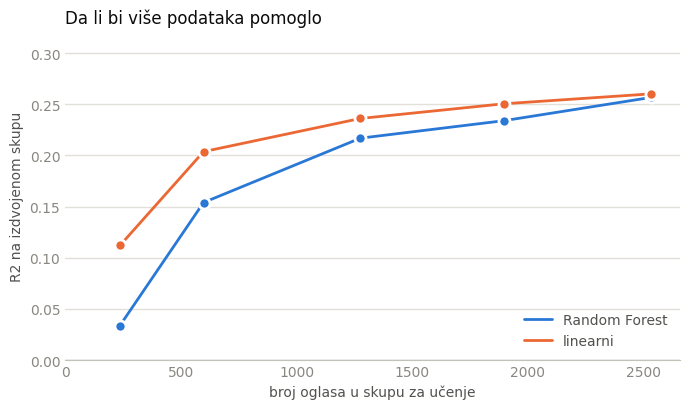

In [9]:
import matplotlib.pyplot as plt

BOJE = {"Random Forest": "#2a78d6", "linearni": "#eb6834"}
TEKST, TEKST_2, BLEDO, MREZA, OSA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"


def uredi_osu(ax) -> None:
    for strana in ("top", "right", "left"):
        ax.spines[strana].set_visible(False)
    ax.spines["bottom"].set_color(OSA)
    ax.tick_params(colors=BLEDO, length=0)
    ax.yaxis.grid(True, color=MREZA, linewidth=1)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(7, 4.2))
x = pregled[("oglasa", "linearni")].to_numpy()
for ime, boja in BOJE.items():
    y_v = pregled[("R²", ime)].to_numpy()
    ax.plot(x, y_v, color=boja, linewidth=2, solid_capstyle="round", label=ime, zorder=2)
    ax.scatter(x, y_v, s=64, color=boja, edgecolor="white", linewidth=2, zorder=3)

uredi_osu(ax)
ax.set_xlim(0, x[-1] * 1.05)
ax.set_ylim(min(0, pregled[("R²", "Random Forest")].min() * 1.2), pregled[("R²", "Random Forest")].max() * 1.25)
ax.axhline(0, color=OSA, linewidth=1)
ax.set_xlabel("broj oglasa u skupu za učenje", color=TEKST_2)
ax.set_ylabel("R² na izdvojenom skupu", color=TEKST_2)
ax.set_title("Da li bi više podataka pomoglo", loc="left", color=TEKST, fontsize=12)
ax.legend(frameon=False, loc="lower right", labelcolor=TEKST_2)
fig.tight_layout()
fig.savefig(FIG / "plata_kriva_ucenja.png", dpi=200)
plt.show()

### Šta se vidi

- Oba modela uče sistematski: R² raste sa svakim povećanjem uzorka.
- Od 1.276 do 2.531 oglasa, dakle skoro dvostruko, linearni model dobija samo
  +0,024. Kriva se spljoštava oko 0,26. Više podataka bi dalo malo; granica nije
  količina podataka, nego to što plata u velikoj meri zavisi od stvari kojih u
  oglasu nema (firma, pregovori, konkretan kandidat).
- Na malim uzorcima slučajna šuma zaostaje (0,03 prema 0,11 na oko 240 oglasa) i
  sustiže linearni model tek na punom skupu.

## 6. Izbor modela

Prethodna sekcija pokazuje da linearni model i Random Forest daju sličan R². Da
se ne bi odlučivalo po razlici koja je možda šum, porede se na istih deset
podela, uparano: ista podela, oba modela, pa razlika.

Dodat je i gradijentni busting, koji je za ovakve tabele obično jači od slučajne
šume. Ako ni on ne nadmaši linearni model, to znači da nelinearnosti nema dovoljno
da bi se isplatila.

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy import stats

X_lin = pd.concat([X_tehnologije, X_lin_posao], axis=1)
X_stablo = pd.concat([X_tehnologije, X_stablo_posao], axis=1)
KATEGORIJE = [X_stablo.columns.get_loc(k) for k in ("drzava", "nivo", "tip")]

MODELI_IZBOR = ("linearni", "Random Forest", "gradijentni busting")


def r2_modela(ime: str, seed: int) -> float:
    if ime in ("linearni", "Random Forest"):
        # isti model kao red "sve" u sekciji 4, pa se ne računa ponovo i brojevi se poklapaju
        return kesiraj(f"oceni|sve|{ime}|{seed}|True", lambda: oceni("sve", ime, seed))["R²"]
    uc, pr = podeli(seed)
    m = HistGradientBoostingRegressor(categorical_features=KATEGORIJE, random_state=42,
                                      max_iter=400, learning_rate=0.05)
    return float(r2_score(y[pr], m.fit(X_stablo.iloc[uc], y[uc]).predict(X_stablo.iloc[pr])))


redovi = [{"seed": seed, **{ime: (kesiraj(f"izbor|{ime}|{seed}", lambda: r2_modela(ime, seed))
                                  if ime == "gradijentni busting" else r2_modela(ime, seed))
                            for ime in MODELI_IZBOR}}
          for seed in SEEDOVI]

izbor = pd.DataFrame(redovi).set_index("seed")
print("R² po podeli:\n")
print(izbor.round(3).to_string())
print(f"\nprosek: {izbor.mean().round(3).to_dict()}")
print(f"raspon linearnog po podelama: {izbor['linearni'].min():.3f} - {izbor['linearni'].max():.3f}")

print("\nuparena poređenja:")
for drugi in ("Random Forest", "gradijentni busting"):
    razlika = izbor["linearni"] - izbor[drugi]
    p = stats.ttest_rel(izbor["linearni"], izbor[drugi]).pvalue
    print(f"   linearni − {drugi:<20} {razlika.mean():+.3f}   linearni bolji na "
          f"{int((razlika > 0).sum())}/{len(izbor)}   p = {p:.3f}")

R² po podeli:

      linearni  Random Forest  gradijentni busting
seed                                              
1        0.308          0.322                0.299
7        0.225          0.246                0.166
42       0.217          0.191                0.177
123      0.259          0.238                0.233
2026     0.292          0.286                0.288
5        0.232          0.271                0.248
11       0.281          0.261                0.272
77       0.253          0.254                0.222
2024     0.271          0.284                0.220
314      0.275          0.317                0.310

prosek: {'linearni': 0.261, 'Random Forest': 0.267, 'gradijentni busting': 0.244}
raspon linearnog po podelama: 0.217 - 0.308

uparena poređenja:
   linearni - Random Forest        -0.006   linearni bolji na 4/10   p = 0.480
   linearni - gradijentni busting  +0.018   linearni bolji na 8/10   p = 0.085


### Zaključak o izboru

Na deset podela linearni model postiže R² 0,261, slučajna šuma 0,267, a
gradijentni busting 0,244. Razlika između linearnog modela i slučajne šume je
-0,006, linearni je bolji na 4 od 10 podela, i razlika nije značajna (p = 0,48).
Busting je slabiji na 8 od 10 podela, ali ni ta razlika ne prelazi uobičajeni
prag (p = 0,085). Razlika između samih podela, od 0,22 do 0,31, je višestruko
veća od razlike između modela.

Tačnost dakle ne odlučuje. Odlučuje tumačivost: koeficijent linearnog modela se
čita direktno kao procentualna razlika u plati, uz standardne greške grupisane po
firmi. Zato je u nastavku glavni model linearni. Rezultat ove sekcije je i nalaz
sam po sebi: nelinearne metode ne donose ništa, pa su doprinosi tehnologija plati
uglavnom aditivni.

## 7. Koje grupe tehnologija najviše utiču

Pojedinačne tehnologije se javljaju zajedno, pa model ne može pošteno da im
razdvoji zasluge: Docker, Kubernetes i Terraform nose sličnu informaciju, i koja
će od njih dobiti koeficijent zavisi od slučajnosti u uzorku.

Zato se važnost meri po grupama iz `02_analiza`, celom klasteru odjednom.
Postupak: vrednosti svih tehnologija jedne grupe se izmešaju između oglasa, čime
se veza sa platom uništava, a zadrži se koliko je često koja tehnologija tražena.
Pad R² pokazuje koliko je ta grupa nosila.

Kao mera za poređenje, isto se radi i sa obeležjima posla odjednom, dakle
lokacija, nivo, tip i veličina firme, da se vidi odnos snaga.

In [11]:
import collections
import itertools

KLASTERI = json.load(open(INTERIM / "graf_meta.json"))["partition"]
clanovi = collections.defaultdict(list)
for t, c in KLASTERI.items():
    clanovi[c].append(t)
clanovi = {c: v for c, v in clanovi.items() if len(v) >= 3}

ucestalost = {t: int(X_tehnologije[t].sum()) for t in TEHNOLOGIJE}
ime_grupe = {c: ", ".join(sorted(v, key=lambda t: -ucestalost[t])[:3]) for c, v in clanovi.items()}
PONAVLJANJA = 10


def vaznost_po_grupama(seed: int) -> dict:
    """Pad R² kada se cela grupa obeležja izmeša između oglasa."""
    uc, pr = podeli(seed)
    m = RidgeCV(alphas=ALFE).fit(X_lin.iloc[uc], y[uc])
    X_pr = X_lin.iloc[pr]
    osnova = r2_score(y[pr], m.predict(X_pr))
    rng = np.random.default_rng(seed)
    grupe_obelezja = {ime_grupe[c]: v for c, v in clanovi.items()}
    grupe_obelezja["(obeležja posla)"] = list(X_lin_posao.columns)
    izlaz = {}
    for naziv, kolone in grupe_obelezja.items():
        padovi = []
        for _ in range(PONAVLJANJA):
            Xp = X_pr.copy()
            Xp[kolone] = Xp[kolone].to_numpy()[rng.permutation(len(Xp))]
            padovi.append(osnova - r2_score(y[pr], m.predict(Xp)))
        izlaz[naziv] = float(np.mean(padovi))
    return izlaz


vaznosti = pd.DataFrame([kesiraj(f"vaznost|{s}", lambda: vaznost_po_grupama(s)) for s in SEEDOVI],
                        index=SEEDOVI)
mesta = vaznosti.rank(axis=1, ascending=False)
pregled = pd.DataFrame({
    "pad R² (prosek)": vaznosti.mean(),
    "odstupanje": vaznosti.std(),
    "mesto (min-max)": [f"{int(mesta[k].min())}-{int(mesta[k].max())}" for k in vaznosti.columns],
    "tehnologija u grupi": [len(clanovi[c]) if naziv != "(obeležja posla)" else X_lin_posao.shape[1]
                            for c, naziv in zip(list(clanovi) + [None], vaznosti.columns)],
}).sort_values("pad R² (prosek)", ascending=False)
print(pregled.round(3).to_string())

                                   pad R² (prosek)  odstupanje mesto (min-max)  tehnologija u grupi
(obeležja posla)                             0.292       0.025             1-1                   60
WINDOWS, ACTIVE DIRECTORY, VMWARE            0.060       0.013             2-3                   18
PYTHON, AZURE, KUBERNETES                    0.043       0.009             2-3                   45
SQL, POWER BI, TABLEAU                       0.021       0.008             4-5                   29
JAVASCRIPT, REACT, C#                        0.012       0.004             4-7                   43
AWS, LAMBDA, S3                              0.006       0.002             5-8                   18
PYTORCH, TENSORFLOW, SCIKIT-LEARN            0.005       0.002             6-8                    3
JAVA, SPRING BOOT, SPRING                    0.002       0.002            6-10                   16
SALESFORCE, APEX, LIGHTNING                  0.000       0.001            8-10                    4


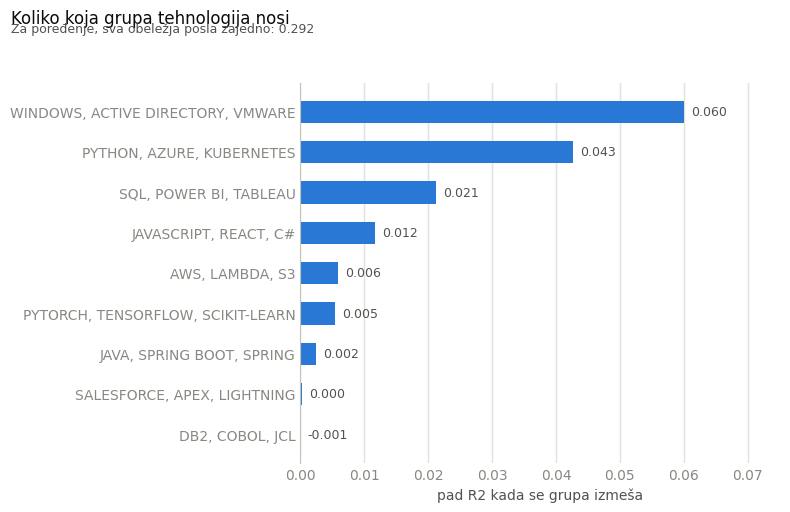

In [12]:
red = pregled.drop(index="(obeležja posla)").sort_values("pad R² (prosek)")
fig, ax = plt.subplots(figsize=(8, 0.42 * len(red) + 1.4))
mesta_y = np.arange(len(red))
ax.barh(mesta_y, red["pad R² (prosek)"].clip(lower=0), height=0.55, color="#2a78d6", zorder=2)
for i, v in enumerate(red["pad R² (prosek)"]):
    ax.annotate(f"{v:.3f}", (max(v, 0), i), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEKST_2)

for strana in ("top", "right", "bottom"):
    ax.spines[strana].set_visible(False)
ax.spines["left"].set_color(OSA)
ax.set_yticks(mesta_y)
ax.set_yticklabels(red.index, color=TEKST_2)
ax.tick_params(colors=BLEDO, length=0)
ax.xaxis.grid(True, color=MREZA, linewidth=1)
ax.set_axisbelow(True)
ax.set_xlim(0, red["pad R² (prosek)"].max() * 1.25)
ax.set_xlabel("pad R² kada se grupa izmeša", color=TEKST_2)
fig.suptitle("Koliko koja grupa tehnologija nosi", x=0.02, ha="left", color=TEKST, fontsize=12)
fig.text(0.02, 0.935, f"Za poređenje, sva obeležja posla zajedno: "
         f"{pregled.loc['(obeležja posla)', 'pad R² (prosek)']:.3f}", ha="left", fontsize=9, color=TEKST_2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "plata_vaznost_grupa.png", dpi=200)
plt.show()

### Šta se vidi

- Obeležja posla zajedno nose oko pet puta više od najjače grupe tehnologija,
  0,292 prema 0,060.
- Dve grupe tehnologija su jasno ispred ostalih: Windows, Active Directory i
  VMware (0,060) i Python, Azure i Kubernetes (0,043). Između njih poredak nije
  stabilan, na pojedinačnim podelama se smenjuju, pa se ne tvrdi koja je jača.
- Slede podaci i BI (0,021) i veb (0,012). AWS i mašinsko učenje nose malo, 0,006
  i 0,005, Java grupa skoro ništa (0,002), a Salesforce i stari mejnfrejm sistemi
  ništa. Tačna mesta u tom delu se po podelama pomeraju, ali nijedna od tih grupa
  ne dostiže dve vodeće.
- Windows grupa je visoko zato što glavni model ne sadrži oblast posla, pa ona
  preuzima informaciju da je oglas za IT podršku. Sekcija 8 to razdvaja.

## 8. Premija po pojedinačnoj tehnologiji

Za svaku tehnologiju koja se javlja u bar 100 oglasa sa platom ocenjuje se
poseban model:

`log(plata) ~ tehnologija + država + nivo iskustva + tip zaposlenja + veličina firme`

Standardne greške su grupisane po firmi, jer ista firma objavljuje više oglasa pa
oni nisu nezavisni. Koeficijent se zbog logaritma čita približno kao procentualna
razlika u plati.

Druga kolona dodaje i oblast posla (`role_family` iz ekstrakcije). Dve kolone
odgovaraju na različita pitanja:

- bez oblasti: koliko više plaćaju oglasi koji traže tu tehnologiju. Ako neko
  naučivši Terraform pređe iz sistem administracije u devops, ta zarada je
  stvarna i ulazi u ovaj broj.
- sa oblašću: koliko više plaćaju oglasi unutar iste struke.

Glavna je prva kolona, jer odgovara pitanju šta da učim. Druga pokazuje odakle
efekat dolazi.

In [13]:
import statsmodels.formula.api as smf

MIN_OGLASA = 100
kandidati = [t for t in TEHNOLOGIJE if ucestalost[t] >= MIN_OGLASA]


def premija(teh: str, sa_oblascu: bool = False) -> tuple[float, float]:
    plate["_x"] = plate["tech"].apply(lambda l: int(l is not None and teh in l)).to_numpy()
    formula = "log_plata ~ _x + C(drzava) + C(nivo) + C(tip) + C(velicina_firme)"
    if sa_oblascu:
        formula += " + C(role_family)"
    m = smf.ols(formula, data=plate).fit(cov_type="cluster", cov_kwds={"groups": plate["firma"]})
    return 100 * (np.exp(m.params["_x"]) - 1), m.pvalues["_x"]


redovi = []
for t in kandidati:
    a, pa = premija(t)
    b, pb = premija(t, sa_oblascu=True)
    redovi.append({"tehnologija": t, "oglasa": ucestalost[t],
                   "premija %": a, "p": pa, "unutar struke %": b, "p ": pb})
premije = pd.DataFrame(redovi).sort_values("premija %", ascending=False).reset_index(drop=True)

znacajne = premije[(premije["p"] < 0.05) & (premije["premija %"].abs() > 5)]
print(f"kandidata (>={MIN_OGLASA} oglasa sa platom): {len(premije)}")
print(f"značajnih (p<0,05) i preko 5 %: {len(znacajne)}\n")
print(pd.concat([premije.head(12), premije.tail(8)]).round(2).to_string(index=False))

kandidata (>=100 oglasa sa platom): 41
značajnih (p<0,05) i preko 5 %: 31

     tehnologija  oglasa  premija %    p  unutar struke %   p 
              GO     148      23.79 0.00            17.00 0.00
           SPARK     116      16.21 0.00            16.43 0.00
             C++     275      15.65 0.00             7.69 0.00
      KUBERNETES     314      14.95 0.00             9.05 0.00
       TERRAFORM     177      14.28 0.00             9.47 0.00
         NODE.JS     154      13.91 0.00             5.43 0.02
           KAFKA     121      13.62 0.00             8.65 0.00
             GCP     211      12.84 0.00             9.57 0.00
             AWS     649      12.59 0.00             8.42 0.00
          PYTHON     975      12.42 0.00             9.94 0.00
      POSTGRESQL     124      12.32 0.00             6.41 0.02
           CI/CD     106      12.05 0.00             5.73 0.06
      POWERSHELL     149      -3.89 0.13            -0.58 0.80
            JIRA     177      -5.41 0.03   

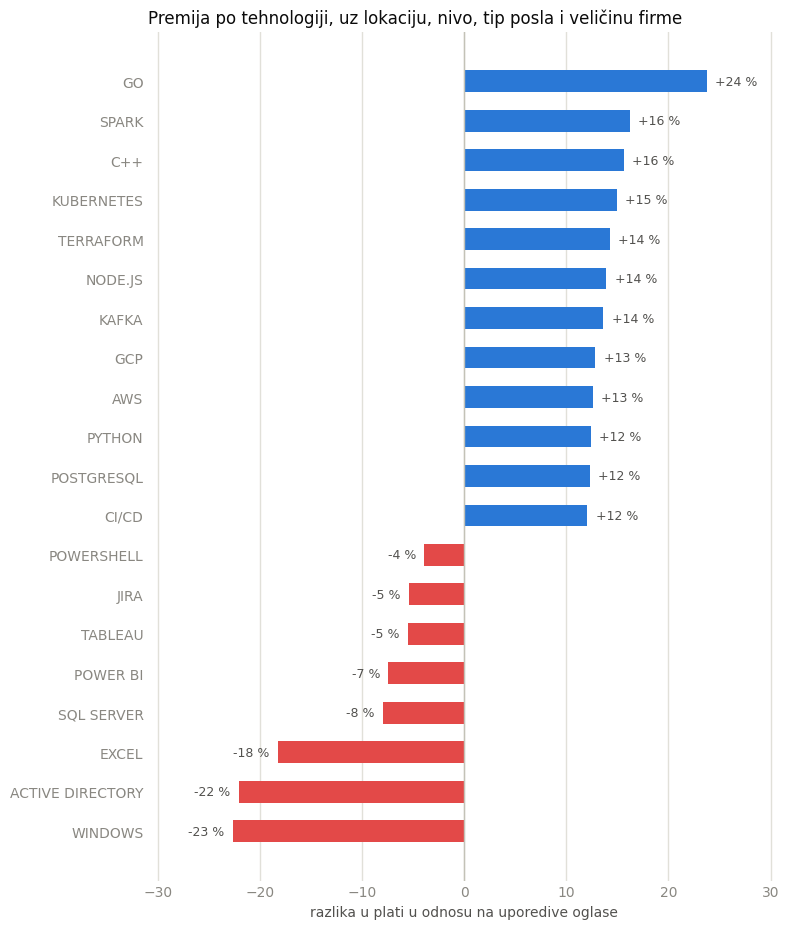

In [14]:
prikaz = pd.concat([premije.head(12), premije.tail(8)]).sort_values("premija %")
boje = ["#e34948" if v < 0 else "#2a78d6" for v in prikaz["premija %"]]

fig, ax = plt.subplots(figsize=(8, 0.4 * len(prikaz) + 1.4))
mesta_y = np.arange(len(prikaz))
ax.barh(mesta_y, prikaz["premija %"], height=0.55, color=boje, zorder=2)
for i, v in zip(mesta_y, prikaz["premija %"]):
    ax.annotate(f"{v:+.0f} %", (v, i), xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right", fontsize=9, color=TEKST_2)

for strana in ("top", "right", "bottom", "left"):
    ax.spines[strana].set_visible(False)
ax.axvline(0, color=OSA, linewidth=1)
ax.set_yticks(mesta_y)
ax.set_yticklabels(prikaz["tehnologija"], color=TEKST_2)
ax.tick_params(colors=BLEDO, length=0)
ax.xaxis.grid(True, color=MREZA, linewidth=1)
ax.set_axisbelow(True)
granica = prikaz["premija %"].abs().max() * 1.3
ax.set_xlim(-granica, granica)
ax.set_xlabel("razlika u plati u odnosu na uporedive oglase", color=TEKST_2)
ax.set_title("Premija po tehnologiji, uz lokaciju, nivo, tip posla i veličinu firme",
             loc="left", color=TEKST, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "plata_premije.png", dpi=200)
plt.show()

### Šta se vidi

- 31 od 41 tehnologije sa bar 100 oglasa ima značajnu razliku u plati veću od 5 %.
- Najveće premije: Go +24 %, Spark +16 %, C++ +16 %, Kubernetes +15 %,
  Terraform +14 %. Najniže: Windows −23 %, Active Directory −22 %, Excel −18 %.
- Druga kolona razdvaja premiju tehnologije od premije vrste posla. Kod Spark-a
  je ista i unutar struke (+16,4 %), kod Go-a većim delom ostaje (+17,0 %), kod
  Pythona je +9,9 %. Kod C++ (+7,7 %) i Node.js (+5,4 %) veći deo premije dolazi
  od toga u kakvim se poslovima traže. Tableau, Jira i Active Directory unutar
  iste struke više nisu značajni.

### Šta koeficijent ne znači

Koeficijent meri oglase, a ne ljude. Ne kaže šta se dešava ako neko nauči
tehnologiju, nego koliko plaćaju oglasi koji je izričito navode kao zahtev.

Razlika je vidljiva na tri vrste tehnologija:

- alati koji se koriste svuda, kao Git i Linux, imaju koeficijent blizu nule i
  nije značajan, jer njihovo pominjanje ne govori ništa o vrsti posla
- oznake vrste posla, kao Windows i Active Directory, imaju jak negativan
  koeficijent, ali više od polovine nestane kada se uporede poslovi iste struke.
  Windows je pre svega znak da je oglas za IT podršku.
- tehnologije uskog ekosistema, kao Go i Kubernetes, zadrže premiju i unutar iste
  struke

Iz tabele dakle sledi da oglasi koji navode Windows kao zahtev pripadaju slabije
plaćenom delu tržišta, a ne da tu tehnologiju ne treba učiti.

In [15]:
poredjenje_vrsta = premije[premije["tehnologija"].isin(
    ["GIT", "LINUX", "WINDOWS", "ACTIVE DIRECTORY", "GO", "KUBERNETES"])].copy()
poredjenje_vrsta["oblast koja ga najviše traži"] = [
    (plate.groupby("role_family")
     .apply(lambda g, t=t: 100 * X_tehnologije.loc[g.index, t].mean())
     .sort_values(ascending=False).head(1).pipe(lambda s: f"{s.index[0]} {s.iloc[0]:.0f} %"))
    for t in poredjenje_vrsta["tehnologija"]]
print(poredjenje_vrsta.round(2).to_string(index=False))

     tehnologija  oglasa  premija %    p  unutar struke %   p  oblast koja ga najviše traži
              GO     148      23.79 0.00            17.00 0.00            devops_cloud 10 %
      KUBERNETES     314      14.95 0.00             9.05 0.00            devops_cloud 28 %
             GIT     277       3.06 0.09            -3.38 0.07    software_engineering 14 %
           LINUX     260       2.08 0.38             2.57 0.25            devops_cloud 17 %
ACTIVE DIRECTORY     105     -22.06 0.00            -5.88 0.09              it_support 18 %
         WINDOWS     167     -22.66 0.00           -10.20 0.00              it_support 25 %


## 9. Širina znanja

Pitanje: da li oglasi koji traže tehnologije iz više različitih oblasti plaćaju
više?

Širina je broj različitih grupa iz mreže u `02_analiza` koje oglas pokriva.
Posmatraju se samo oglasi sa bar jednom tehnologijom iz mreže, jer oglas bez njih
ima širinu nula iz tehničkog razloga, a ne zato što je uzak.

Dva modela, oba sa obeležjima posla:

- samo širina
- širina i broj tehnologija, da se razdvoji više oblasti od više tehnologija

In [16]:
OBELEZJA_POSLA_FORMULA = "C(drzava) + C(nivo) + C(tip) + C(velicina_firme)"

plate["broj_u_mrezi"] = plate["tech"].apply(lambda l: sum(t in KLASTERI for t in (l if l is not None else [])))
plate["sirina"] = plate["tech"].apply(lambda l: len({KLASTERI[t] for t in (l if l is not None else []) if t in KLASTERI}))
sa_mrezom = plate[plate["broj_u_mrezi"] > 0].copy()

print(f"oglasa sa bar jednom tehnologijom iz mreže: {len(sa_mrezom):,} od {len(plate):,}")
print(f"širina: prosek {sa_mrezom['sirina'].mean():.2f}, raspodela "
      f"{sa_mrezom['sirina'].clip(upper=5).value_counts().sort_index().to_dict()}  (5 = pet i više)")
rho = stats.spearmanr(sa_mrezom["sirina"], sa_mrezom["log_plata"])
print(f"sirova veza sa platom: Spearman ρ = {rho.statistic:.3f} (p = {rho.pvalue:.1e})\n")

for naziv, desno in [("samo širina", "sirina"), ("širina i broj tehnologija", "sirina + broj_u_mrezi")]:
    m = smf.ols(f"log_plata ~ {desno} + {OBELEZJA_POSLA_FORMULA}", data=sa_mrezom).fit(
        cov_type="cluster", cov_kwds={"groups": sa_mrezom["firma"]})
    delovi = [f"{k}: {100 * (np.exp(m.params[k]) - 1):+.1f} % po jedinici (p = {m.pvalues[k]:.3f})"
              for k in desno.split(" + ")]
    print(f"{naziv:<28} " + "   ".join(delovi))

oglasa sa bar jednom tehnologijom iz mreže: 2,789 od 3,411
širina: prosek 2.31, raspodela {1: 857, 2: 859, 3: 600, 4: 324, 5: 149}  (5 = pet i više)
sirova veza sa platom: Spearman ρ = 0.130 (p = 6.2e-12)

samo širina                  sirina: +2.9 % po jedinici (p = 0.000)
širina i broj tehnologija    sirina: +1.8 % po jedinici (p = 0.018)   broj_u_mrezi: +0.5 % po jedinici (p = 0.026)


### Šta se vidi

- Oglasi sa tehnologijama iz više grupa plaćaju nešto više, +2,9 % po dodatnoj
  grupi, uz obeležja posla.
- Deo toga je samo to što takvi oglasi traže više tehnologija. Kada se uzme u
  obzir i broj tehnologija, širina i dalje nosi +1,8 % po grupi (p = 0,018), a
  svaka dodatna tehnologija +0,5 % (p = 0,026).
- Efekat je stvaran, ali mali: oglas koji pokriva četiri grupe umesto jedne plaća
  oko 5 % više.
- Ograničenje: tehnologije van mreže se ne broje, pa oglasi sa retkim
  tehnologijama izgledaju uže nego što jesu.

## 10. Spajanje sa preporukom

`03_preporuka` daje listu predloga, a ovaj notebook procenu plate po tehnologiji.
Ovde se spajaju, pa uz svaki predlog ide i premija.

Zajednička ocena se ne pravi. Da bi se povezanost i premija sabrale u jedan broj,
morala bi se izabrati težina, na primer koliko vredi 10 % plate u odnosu na 0,1
pouzdanosti, a svaki takav izbor je proizvoljan. Isti razlog je i u `03` doveo do
spajanja po mestima na listi umesto po ocenama. Zato obe informacije stoje jedna
pored druge.

Model preporuke se ne uči ponovo, nego se učitava iz fajlova koje je sačuvao
`03`. Funkcije su prepisane iz `03`, a provera odmah ispod potvrđuje da daju iste
predloge.

Za spajanje se premija računa za sve tehnologije sa bar 50 oglasa sa platom, a ne
100 kao u sekciji 8, da bi više predloga imalo procenu. Uz svaku premiju je i
p-vrednost, pa se nepouzdane procene vide.

In [17]:
pravila_disk = pd.read_parquet(INTERIM / "preporuka_pravila.parquet")
lift_disk = pd.read_parquet(INTERIM / "preporuka_lift.parquet")
popularnost_disk = pd.read_parquet(INTERIM / "preporuka_popularnost.parquet")

POP_RANG = popularnost_disk.sort_values("rang")["tehnologija"].tolist()
POP_POZICIJA = {t: i for i, t in enumerate(POP_RANG)}
MAX_USLOV = 2

PRAVILA = collections.defaultdict(list)
for uslov, predlog, pouzdanost in zip(pravila_disk["uslov"], pravila_disk["preporuka"], pravila_disk["pouzdanost"]):
    PRAVILA[frozenset(uslov.split(" + "))].append((predlog, pouzdanost))
LIFT = collections.defaultdict(dict)
for a, b, v in zip(lift_disk["tehnologija_a"], lift_disk["tehnologija_b"], lift_disk["lift"]):
    LIFT[a][b] = LIFT[b][a] = v


def dopuni_po_popularnosti(skor: dict, zna: set, n: int) -> list[str]:
    lista = sorted((t for t in skor if t not in zna), key=lambda t: (-skor[t], POP_POZICIJA[t]))
    for t in POP_RANG:
        if len(lista) >= n:
            break
        if t not in zna and t not in skor:
            lista.append(t)
    return lista[:n]


def preporuci_apriori(zna: set, n: int = 10) -> list[str]:
    skor = {}
    for velicina in range(1, MAX_USLOV + 1):
        for uslov in itertools.combinations(sorted(zna), velicina):
            for predlog, pouzdanost in PRAVILA.get(frozenset(uslov), ()):
                skor[predlog] = max(skor.get(predlog, 0.0), pouzdanost)
    return dopuni_po_popularnosti(skor, zna, n)


def preporuci_lift(zna: set, n: int = 10) -> list[str]:
    skor = collections.defaultdict(float)
    for x in zna:
        for y_, v in LIFT.get(x, {}).items():
            if v > 1:
                skor[y_] += np.log(v)
    return dopuni_po_popularnosti(dict(skor), zna, n)


def preporuci_hibridni(zna: set, n: int = 10) -> list[str]:
    liste = (preporuci_apriori(zna, n), preporuci_lift(zna, n))
    spoj = []
    for i in range(n):
        for lista in liste:
            if len(spoj) == n:
                return spoj
            if i < len(lista) and lista[i] not in spoj:
                spoj.append(lista[i])
    return spoj


# provera: isti predlozi kao u sekciji 12 notebooka 03
assert preporuci_hibridni({"JAVA", "SPRING BOOT"}, 5) == ["PYTHON", "JPA", "AWS", "HIBERNATE", "JENKINS"]
assert preporuci_hibridni({"EXCEL", "TABLEAU"}, 5) == ["SQL", "QLIK", "PYTHON", "ALTERYX", "POWER BI"]
print(f"model preporuke učitan: {len(POP_RANG)} tehnologija, {len(pravila_disk):,} pravila, "
      f"{len(lift_disk):,} parova, predlozi se poklapaju sa 03")

model preporuke učitan: 280 tehnologija, 3,921 pravila, 7,737 parova, predlozi se poklapaju sa 03


In [18]:
MIN_ZA_SPAJANJE = 50
sa_platom_ukupno = Counter(t for l in plate["tech"] if l is not None for t in set(l))
za_procenu = [t for t in POP_RANG if sa_platom_ukupno[t] >= MIN_ZA_SPAJANJE]

procene = pd.DataFrame([
    {"tehnologija": t, "oglasa sa platom": sa_platom_ukupno[t],
     **dict(zip(("premija %", "p"), kesiraj(f"premija|{t}|False", lambda: list(premija(t)))))}
    for t in za_procenu
]).set_index("tehnologija")

print(f"tehnologija u modelu preporuke: {len(POP_RANG)}")
print(f"sa bar {MIN_ZA_SPAJANJE} oglasa sa platom (ima procenu): {len(procene)}")
print(f"   od toga značajno i preko +5 %: {int(((procene['p'] < 0.05) & (procene['premija %'] > 5)).sum())}")
print(f"   od toga značajno i ispod −5 %: {int(((procene['p'] < 0.05) & (procene['premija %'] < -5)).sum())}")

tehnologija u modelu preporuke: 280
sa bar 50 oglasa sa platom (ima procenu): 71
   od toga značajno i preko +5 %: 31
   od toga značajno i ispod −5 %: 11


### Predlozi sa premijom

Za nekoliko polaznih skupova: deset predloga hibridnog modela, odakle predlog
dolazi (Apriori, lift ili oba), i premija ako postoji dovoljno oglasa sa platom.

In [19]:
PRIMERI = [{"PYTHON", "SQL"}, {"JAVA", "SPRING BOOT"}, {"JAVASCRIPT", "REACT"},
           {"AWS", "TERRAFORM"}, {"ACTIVE DIRECTORY", "WINDOWS"}, {"TABLEAU", "EXCEL"}]


def predlozi_sa_platom(zna: set, n: int = 10) -> pd.DataFrame:
    a, l = set(preporuci_apriori(zna, n)), set(preporuci_lift(zna, n))
    redovi = []
    for mesto, t in enumerate(preporuci_hibridni(zna, n), start=1):
        izvor = "oba" if t in a and t in l else "Apriori" if t in a else "lift"
        red = {"mesto": mesto, "predlog": t, "izvor": izvor}
        if t in procene.index:
            p = procene.loc[t]
            red |= {"premija %": round(p["premija %"], 1), "p": round(p["p"], 3),
                    "pouzdano": "da" if p["p"] < 0.05 else "ne"}
        else:
            red |= {"premija %": np.nan, "p": np.nan, "pouzdano": "malo podataka"}
        redovi.append(red)
    return pd.DataFrame(redovi)


primeri_sa_platom = []
for zna in PRIMERI:
    tabela = predlozi_sa_platom(zna)
    print(f"\nzna: {', '.join(sorted(zna))}")
    print(tabela.to_string(index=False))
    primeri_sa_platom.append(tabela.assign(zna=", ".join(sorted(zna))))


zna: PYTHON, SQL
 mesto    predlog   izvor  premija %     p      pouzdano
     1        AWS Apriori       12.6 0.000            da
     2          R     oba        2.1 0.542            ne
     3       JAVA Apriori       11.3 0.000            da
     4     PANDAS    lift        NaN   NaN malo podataka
     5    AIRFLOW    lift        NaN   NaN malo podataka
     6    TABLEAU Apriori       -5.5 0.026            da
     7        DBT    lift        NaN   NaN malo podataka
     8      AZURE Apriori        5.6 0.003            da
     9      NUMPY    lift        NaN   NaN malo podataka
    10 KUBERNETES Apriori       15.0 0.000            da

zna: JAVA, SPRING BOOT
 mesto   predlog   izvor  premija %     p      pouzdano
     1    PYTHON Apriori       12.4 0.000            da
     2       JPA    lift        NaN   NaN malo podataka
     3       AWS Apriori       12.6 0.000            da
     4 HIBERNATE    lift        NaN   NaN malo podataka
     5   JENKINS Apriori        7.2 0.002          


zna: ACTIVE DIRECTORY, WINDOWS
 mesto        predlog   izvor  premija %     p      pouzdano
     1          LINUX Apriori        2.1 0.380            ne
     2          MACOS    lift        NaN   NaN malo podataka
     3          AZURE Apriori        5.6 0.003            da
     4       EXCHANGE    lift        NaN   NaN malo podataka
     5     POWERSHELL Apriori       -3.9 0.126            ne
     6           SCCM    lift        NaN   NaN malo podataka
     7         VMWARE Apriori      -13.1 0.000            da
     8         CITRIX    lift        NaN   NaN malo podataka
     9 WINDOWS SERVER Apriori        NaN   NaN malo podataka
    10           O365    lift        NaN   NaN malo podataka

zna: EXCEL, TABLEAU
 mesto   predlog   izvor  premija %     p      pouzdano
     1       SQL Apriori       -3.4 0.020            da
     2      QLIK    lift        NaN   NaN malo podataka
     3    PYTHON Apriori       12.4 0.000            da
     4   ALTERYX    lift        NaN   NaN malo podat

### Koliko predloga uopšte ima procenu plate

Za svaki IT oglas se kao ulaz uzmu njegove tehnologije i traži deset predloga.
Meri se koliki deo predloga ima procenu premije, i kakva je ta premija, posebno
za predloge koji dolaze od Apriorija i od lifta.

In [20]:
U_MODELU = set(POP_RANG)
korpe = [s for s in (set(l) & U_MODELU for l in it["tech"] if l is not None) if s]

redovi = []
for zna in korpe:
    a, l = set(preporuci_apriori(zna)), set(preporuci_lift(zna))
    for t in preporuci_hibridni(zna):
        izvor = "oba" if t in a and t in l else "Apriori" if t in a else "lift"
        ima = t in procene.index
        redovi.append({"izvor": izvor, "ima procenu": ima,
                       "značajno +": ima and procene.at[t, "p"] < 0.05 and procene.at[t, "premija %"] > 5,
                       "značajno −": ima and procene.at[t, "p"] < 0.05 and procene.at[t, "premija %"] < -5})
pokrice = pd.DataFrame(redovi)

pregled_pokrica = pokrice.groupby("izvor")[["ima procenu", "značajno +", "značajno −"]].mean().mul(100)
pregled_pokrica["predloga"] = pokrice.groupby("izvor").size()
pregled_pokrica.loc["ukupno"] = [*(pokrice[["ima procenu", "značajno +", "značajno −"]].mean() * 100), len(pokrice)]
print(f"oglasa: {len(korpe):,} | predloga: {len(pokrice):,}\n")
print(pregled_pokrica.round(1).to_string())

oglasa: 9,868 | predloga: 98,680

         ima procenu  značajno +  značajno -  predloga
izvor                                                 
Apriori         99.1        74.0         4.5   44014.0
lift             9.1         3.4         1.5   43540.0
oba             82.9        38.6        16.4   11126.0
ukupno          57.6        38.8         4.5   98680.0


### Šta se vidi

- Procena premije postoji za 71 od 280 tehnologija iz modela preporuke. Za ostale
  nema bar 50 oglasa sa navedenom platom.
- To nije ravnomerno raspoređeno. Predlozi Apriorija imaju procenu u 99 %
  slučajeva, a predlozi lifta u 9 %. Lift predlaže specifične tehnologije (JPA,
  Hibernate, Airflow, dbt), a upravo za njih nema dovoljno oglasa sa platom.
- Od Apriorijevih predloga, 74 % ima značajnu premiju veću od +5 %. Apriori
  predlaže tražene tehnologije, a među procenjenim tehnologijama je više onih sa
  pozitivnom premijom (31) nego sa negativnom (11).
- Vrednost spajanja vidi se unutar jednog polaznog skupa. Kandidatu koji zna Excel
  i Tableau Apriori na vrhu liste predlaže SQL, Python, Power BI, R i Snowflake, a
  premije tih predloga idu od −7 % (Power BI) do +12 % (Python).

Ograničenje: hibridni model predlaže i specifične tehnologije koje ovi podaci ne
mogu da procene. Za njih se dobija samo povezanost, bez premije.

## 11. Čuvanje

Upisuju se tabela premija iz sekcije 8 (obe kolone), procene za sve tehnologije
sa bar 50 oglasa sa platom, i primeri predloga sa premijom.

In [21]:
premije.to_parquet(INTERIM / "plata_premije.parquet", index=False)
procene.reset_index().to_parquet(INTERIM / "plata_procene_za_preporuku.parquet", index=False)
pd.concat(primeri_sa_platom).to_parquet(INTERIM / "plata_primeri_preporuka.parquet", index=False)
for f in ("plata_premije", "plata_procene_za_preporuku", "plata_primeri_preporuka"):
    print(f"{f + '.parquet':<36} {len(pd.read_parquet(INTERIM / (f + '.parquet'))):>5} redova")

plata_premije.parquet                   41 redova
plata_procene_za_preporuku.parquet      71 redova
plata_primeri_preporuka.parquet         60 redova
